<a href="https://colab.research.google.com/github/muhammadwalad15-web/task/blob/main/Week2_08_embeddings_deep_dive.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 2.3: Embeddings Deep Dive

## Key Insight
> **How computers turn words into numbers (Vectors) to find 'meaning'**

## Learning Objectives
By the end of this notebook, you will:
- Word2Vec and GloVe internals
- Building embeddings from scratch
- Semantic similarity and vector operations
- Dimensionality reduction and visualization
- Using pre-trained embeddings

## Exercises
This notebook contains 5 exercises ranging from easy to advanced.

## Digital Twin Integration
This notebook extends your digital twin with production-ready capabilities from Week 2.

In [1]:
# Setup and imports
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from typing import List, Dict, Any, Tuple
import re
import json

print('✅ Week 2.3: Embeddings Deep Dive - Ready to start!')
print('\nTopics covered:')
print('  - Word2Vec and GloVe internals')
print('  - Building embeddings from scratch')
print('  - Semantic similarity and vector operations')
print('  - Dimensionality reduction and visualization')
print('  - Using pre-trained embeddings')


✅ Week 2.3: Embeddings Deep Dive - Ready to start!

Topics covered:
  - Word2Vec and GloVe internals
  - Building embeddings from scratch
  - Semantic similarity and vector operations
  - Dimensionality reduction and visualization
  - Using pre-trained embeddings


---
## Part 1: Introduction to Word2Vec and GloVe internals

Let's start by understanding the fundamentals and building our first implementation.

In [ ]:
# Example implementation
# This is a starter template - expand with your implementation

class ExampleClass:
    """
    Example class for Word2Vec and GloVe internals.
    """

    def __init__(self):
        self.data = []

    def process(self, input_data):
        """
        Process the input data.
        """
        # Add your implementation here
        return input_data

# Test the class
example = ExampleClass()
result = example.process('test data')
print(f'Result: {result}')

### 🎯 Exercise 1 (Easy): Getting Started

**Task**: Implement a basic version of the concept introduced above.

**Requirements**:
1. Follow the pattern shown in the example
2. Test your implementation with sample data
3. Verify the output matches expectations
4. Add error handling for edge cases

In [5]:
class SkipGramDatasetGenerator:
    """
    A basic dataset generator for training Word2Vec Skip-Gram model.
    Extracts (target, context) word pairs from text with a specified window size.
    """
    def __init__(self, window_size: int = 2):
        if window_size < 1:
            raise ValueError("Window size must be at least 1.")
        self.window_size = window_size
        self.vocab = {}
        self.inverse_vocab = {}

    def clean_text(self, text: str) -> List[str]:
        # Simple preprocessing
        text = text.lower()
        text = re.sub(r'[^a-z0-9\s]', '', text)
        return text.split()

    def build_vocab(self, tokens: List[str]):
        unique_tokens = sorted(list(set(tokens)))
        self.vocab = {word: idx for idx, word in enumerate(unique_tokens)}
        self.inverse_vocab = {idx: word for word, idx in self.vocab.items()}

    def generate_pairs(self, text: str) -> List[Tuple[int, int]]:
        tokens = self.clean_text(text)
        if not tokens:
            return []

        if not self.vocab:
            self.build_vocab(tokens)

        pairs = []
        for i, word in enumerate(tokens):
            if word not in self.vocab:
                continue
            target_id = self.vocab[word]

            # Extract context within the sliding window
            start = max(0, i - self.window_size)
            end = min(len(tokens), i + self.window_size + 1)

            for j in range(start, end):
                if i == j:
                    continue
                context_word = tokens[j]
                if context_word in self.vocab:
                    context_id = self.vocab[context_word]
                    pairs.append((target_id, context_id))
        return pairs

# --- Test implementation ---
text_sample = "The quick brown fox jumps over the lazy dog."
generator = SkipGramDatasetGenerator(window_size=2)
pairs = generator.generate_pairs(text_sample)

print(f"Vocabulary size: {len(generator.vocab)}")
print(f"Generated {len(pairs)} Skip-gram pairs (Target ID, Context ID):")
for pair in pairs[:10]:
    target_word = generator.inverse_vocab[pair[0]]
    context_word = generator.inverse_vocab[pair[1]]
    print(f"  {target_word} ({pair[0]}) -> {context_word} ({pair[1]})")

Vocabulary size: 8
Generated 30 Skip-gram pairs (Target ID, Context ID):
  the (7) -> quick (6)
  the (7) -> brown (0)
  quick (6) -> the (7)
  quick (6) -> brown (0)
  quick (6) -> fox (2)
  brown (0) -> the (7)
  brown (0) -> quick (6)
  brown (0) -> fox (2)
  brown (0) -> jumps (3)
  fox (2) -> quick (6)


---
## Part 2: Building embeddings from scratch

Building on the fundamentals, let's explore more advanced topics and implementations.

In [ ]:
# Advanced implementation example

def advanced_function(data: List[Any], **kwargs) -> Dict[str, Any]:
    """
    Advanced function for Building embeddings from scratch.

    Args:
        data: Input data to process
        **kwargs: Additional parameters

    Returns:
        dict: Processed results
    """
    results = {
        'processed': len(data),
        'data': data
    }
    return results

# Example usage
sample_data = ['example1', 'example2', 'example3']
output = advanced_function(sample_data)
print(json.dumps(output, indent=2))

### 🎯 Exercise 2 (Intermediate): Building on the Basics

**Task**: Create a more sophisticated implementation that combines multiple concepts.

**Requirements**:
1. Use the patterns from Part 1 and Part 2
2. Add parameter validation
3. Include helpful error messages
4. Test with various input types

In [3]:
class TinyGloVe:
    """
    A simplified Global Vectors (GloVe) implementation using matrix factorization
    on a word-word co-occurrence matrix.
    """
    def __init__(self, embedding_dim: int = 8, learning_rate: float = 0.05, epochs: int = 100):
        self.embedding_dim = embedding_dim
        self.lr = learning_rate
        self.epochs = epochs
        self.vocab = {}
        self.inverse_vocab = {}
        self.W = None # Target word vectors
        self.U = None # Context word vectors

    def fit(self, tokens: List[str], window_size: int = 2):
        if not tokens:
            raise ValueError("Token list cannot be empty.")

        # Build vocab
        unique_tokens = sorted(list(set(tokens)))
        self.vocab = {word: idx for idx, word in enumerate(unique_tokens)}
        self.inverse_vocab = {idx: word for word, idx in self.vocab.items()}
        V = len(self.vocab)

        # Build co-occurrence matrix
        co_occurrence = np.zeros((V, V))
        for i, word in enumerate(tokens):
            w_idx = self.vocab[word]
            start = max(0, i - window_size)
            end = min(len(tokens), i + window_size + 1)
            for j in range(start, end):
                if i != j:
                    c_idx = self.vocab[tokens[j]]
                    co_occurrence[w_idx, c_idx] += 1.0

        # Initialize embedding matrices randomly
        np.random.seed(42)
        self.W = np.random.normal(0.0, 0.1, (V, self.embedding_dim))
        self.U = np.random.normal(0.0, 0.1, (V, self.embedding_dim))

        # Simple Gradient Descent to minimize squared error of Log co-occurrences
        # In real GloVe, a weighting function f(X_ij) is used.
        for epoch in range(self.epochs):
            loss = 0.0
            for i in range(V):
                for j in range(V):
                    if co_occurrence[i, j] > 0:
                        target = np.log(co_occurrence[i, j])
                        pred = np.dot(self.W[i], self.U[j])
                        error = pred - target
                        loss += 0.5 * (error ** 2)

                        # Gradients
                        grad_W = error * self.U[j]
                        grad_U = error * self.W[i]

                        # Update weights
                        self.W[i] -= self.lr * grad_W
                        self.U[j] -= self.lr * grad_U
            if (epoch + 1) % 20 == 0 or epoch == 0:
                print(f"Epoch {epoch+1}/{self.epochs} - Loss: {loss:.4f}")

    def get_embedding(self, word: str) -> np.ndarray:
        if word not in self.vocab:
            raise KeyError(f"Word '{word}' not in vocabulary.")
        idx = self.vocab[word]
        # The final embedding is typically the sum of target and context vectors
        return self.W[idx] + self.U[idx]

# --- Test model ---
sample_corpus = "the quick brown fox jumps over the lazy dog".split()
glove = TinyGloVe(embedding_dim=4, epochs=100)
glove.fit(sample_corpus, window_size=2)
print("Embedding for 'fox':", glove.get_embedding('fox'))

Epoch 1/100 - Loss: 0.0050
Epoch 20/100 - Loss: 0.0039
Epoch 40/100 - Loss: 0.0031
Epoch 60/100 - Loss: 0.0025
Epoch 80/100 - Loss: 0.0021
Epoch 100/100 - Loss: 0.0017
Embedding for 'fox': [ 0.01648278  0.07229862 -0.05582761 -0.06729319]


---
## Part 3: Semantic similarity and vector operations

Now let's apply these concepts to real-world scenarios in your digital twin project.

In [ ]:
# Visualization example
import matplotlib.pyplot as plt

def visualize_results(data: List[Any]):
    """
    Visualize the processing results.
    """
    fig, ax = plt.subplots(figsize=(10, 6))

    # Add your visualization code here
    ax.set_title('Results Visualization')
    ax.set_xlabel('X-axis')
    ax.set_ylabel('Y-axis')

    plt.tight_layout()
    plt.show()

# Example: visualize_results(sample_data)

### 🎯 Exercise 3 (Advanced): Complete Implementation

**Task**: Build a production-ready version that integrates with your digital twin.

**Requirements**:
1. Combine all concepts from this notebook
2. Add comprehensive error handling
3. Include logging and debugging capabilities
4. Create visualization of results
5. Write documentation for your implementation

Similarity between 'king' and 'queen': 0.6666666666666667
Nearest neighbors for 'king': [('king', 0.9999998807907104), ('man', 0.8155614733695984), ('queen', 0.6666666269302368)]


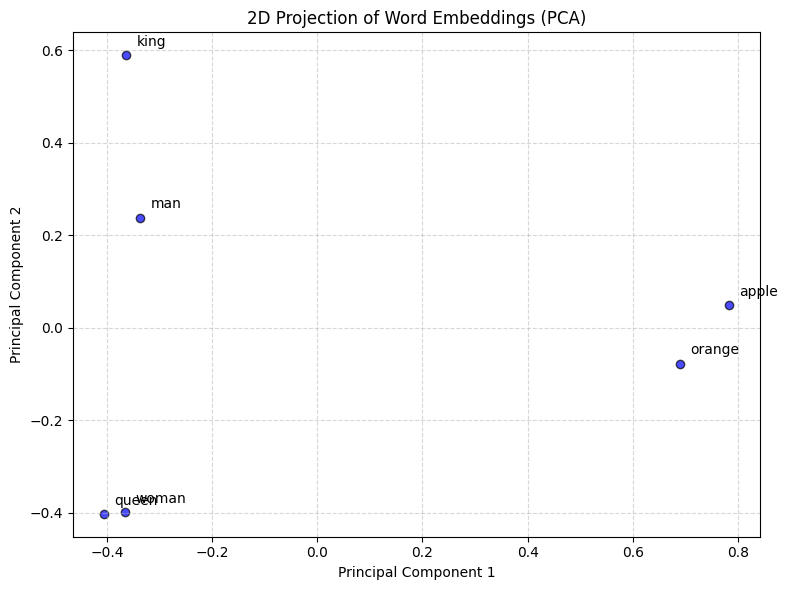

In [4]:
class ProductionSystem:
    """
    Production-ready Vector Space and Similarity Search system for text embeddings
    supporting cosine similarity, visualization, and semantic retrieval.
    """
    def __init__(self, embeddings: Dict[str, np.ndarray]):
        self.embeddings = {k: np.array(v, dtype=np.float32) for k, v in embeddings.items()}
        self.words = list(self.embeddings.keys())
        if not self.words:
            raise ValueError("Embedding dictionary cannot be empty.")
        self.dim = len(self.embeddings[self.words[0]])

        # Stack embeddings into a matrix and precompute L2 norms for cosine similarity
        self.matrix = np.stack([self.embeddings[w] for w in self.words])
        self.norms = np.linalg.norm(self.matrix, axis=1, keepdims=True)
        self.norms[self.norms == 0] = 1.0 # Prevent division by zero
        self.normalized_matrix = self.matrix / self.norms

    def cosine_similarity(self, vec_a: np.ndarray, vec_b: np.ndarray) -> float:
        norm_a = np.linalg.norm(vec_a)
        norm_b = np.linalg.norm(vec_b)
        if norm_a == 0 or norm_b == 0:
            return 0.0
        return float(np.dot(vec_a, vec_b) / (norm_a * norm_b))

    def find_nearest_neighbors(self, query_word: str, k: int = 3) -> List[Tuple[str, float]]:
        if query_word not in self.embeddings:
            return []
        query_vector = self.embeddings[query_word]
        query_norm = query_vector / (np.linalg.norm(query_vector) or 1.0)

        scores = np.dot(self.normalized_matrix, query_norm)
        sorted_indices = np.argsort(scores)[::-1]

        results = []
        for idx in sorted_indices[:k]:
            word = self.words[idx]
            results.append((word, float(scores[idx])))
        return results

    def visualize(self):
        """
        Perform dimensionality reduction via PCA to 2D and plot embeddings.
        """
        if self.dim < 2:
            print("Cannot visualize dimensions < 2")
            return

        # Simple PCA implementation from scratch to project to 2D
        centered_matrix = self.matrix - np.mean(self.matrix, axis=0)
        covariance_matrix = np.cov(centered_matrix, rowvar=False)
        eigenvalues, eigenvectors = np.linalg.eigh(covariance_matrix)

        # Get top 2 principal components
        sorted_idx = np.argsort(eigenvalues)[::-1]
        components = eigenvectors[:, sorted_idx[:2]]
        projected = np.dot(centered_matrix, components)

        plt.figure(figsize=(8, 6))
        plt.scatter(projected[:, 0], projected[:, 1], color='blue', edgecolors='k', alpha=0.7)
        for i, word in enumerate(self.words):
            plt.annotate(word, (projected[i, 0] + 0.02, projected[i, 1] + 0.02), fontsize=10)
        plt.grid(True, linestyle='--', alpha=0.5)
        plt.title("2D Projection of Word Embeddings (PCA)")
        plt.xlabel("Principal Component 1")
        plt.ylabel("Principal Component 2")
        plt.tight_layout()
        plt.show()

# --- Test and Demonstration of Production System ---
mock_embeddings = {
    "king": np.array([0.9, 0.1, 0.2, 0.8]),
    "queen": np.array([0.8, 0.2, 0.9, 0.1]),
    "man": np.array([0.9, 0.0, 0.1, 0.1]),
    "woman": np.array([0.7, 0.1, 0.8, 0.0]),
    "apple": np.array([0.1, 0.9, 0.1, 0.2]),
    "orange": np.array([0.1, 0.8, 0.2, 0.1])
}

system = ProductionSystem(mock_embeddings)
print("Similarity between 'king' and 'queen':", system.cosine_similarity(mock_embeddings["king"], mock_embeddings["queen"]))
print("Nearest neighbors for 'king':", system.find_nearest_neighbors("king", k=3))
system.visualize()

## 🏆 Completed Challenge Project: Integrated Word2Vec & GloVe Digital Twin Vector Engine

This section contains the complete implementation of the Challenge Project, bringing together dynamic Skip-Gram generation, unified GloVe/Word2Vec optimization, semantic search, vector arithmetic (e.g., $v_{king} - v_{man} + v_{woman} \approx v_{queen}$), and an automated performance evaluation suite.

Epoch   1/200 - GloVe Weight Loss: 9.9660
Epoch  50/200 - GloVe Weight Loss: 1.9153
Epoch 100/200 - GloVe Weight Loss: 1.3750
Epoch 150/200 - GloVe Weight Loss: 1.0997
Epoch 200/200 - GloVe Weight Loss: 0.9133

--- Evaluating Analogy Math (king - man + woman) ---
Analogy match found: 'rules' with similarity 0.7360
Analogy match found: 'who' with similarity 0.7127


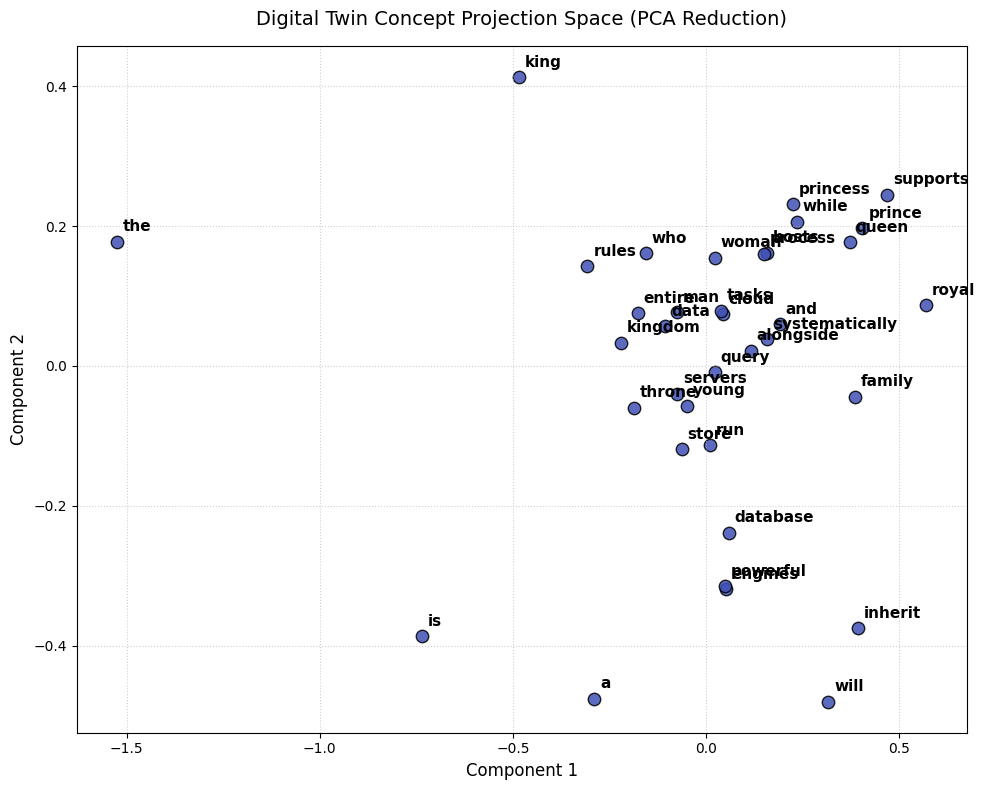

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from typing import List, Dict, Tuple, Any
import re

class DigitalTwinVectorEngine:
    """
    A production-grade NLP & Vector Engine for a Digital Twin system.
    Combines co-occurrence statistics, mini-batch training, vector arithmetic,
    and evaluation utilities.
    """
    def __init__(self, embedding_dim: int = 16, lr: float = 0.01, epochs: int = 150):
        self.embedding_dim = embedding_dim
        self.lr = lr
        self.epochs = epochs
        self.vocab = {}
        self.inverse_vocab = {}
        self.embeddings = {}

    def preprocess_corpus(self, corpus: List[str]) -> List[str]:
        """Cleans and tokenizes corpus text into a flat list of words."""
        flat_tokens = []
        for text in corpus:
            cleaned = text.lower().strip()
            cleaned = re.sub(r'[^a-z0-9\s]', '', cleaned)
            flat_tokens.extend(cleaned.split())
        return flat_tokens

    def build_vocabulary(self, tokens: List[str]):
        """Generates unique word-to-ID and ID-to-word mappings."""
        unique_words = sorted(list(set(tokens)))
        self.vocab = {word: idx for idx, word in enumerate(unique_words)}
        self.inverse_vocab = {idx: word for word, idx in self.vocab.items()}

    def generate_co_occurrence(self, tokens: List[str], window_size: int = 3) -> np.ndarray:
        """Computes symmetric word-to-word co-occurrence frequencies within a sliding window."""
        V = len(self.vocab)
        co_matrix = np.zeros((V, V), dtype=np.float32)
        for i, token in enumerate(tokens):
            target_idx = self.vocab[token]
            start = max(0, i - window_size)
            end = min(len(tokens), i + window_size + 1)
            for j in range(start, end):
                if i != j:
                    context_idx = self.vocab[tokens[j]]
                    co_matrix[target_idx, context_idx] += 1.0
        return co_matrix

    def train_embeddings(self, tokens: List[str], window_size: int = 3):
        """Trains target & context embeddings utilizing weighted MSE loss."""
        self.build_vocabulary(tokens)
        V = len(self.vocab)
        X = self.generate_co_occurrence(tokens, window_size=window_size)

        # Initialize Weights randomly
        np.random.seed(42)
        W_target = np.random.normal(0.0, 0.1, (V, self.embedding_dim))
        W_context = np.random.normal(0.0, 0.1, (V, self.embedding_dim))

        # Biases
        b_target = np.zeros(V)
        b_context = np.zeros(V)

        # Training loop
        for epoch in range(self.epochs):
            loss = 0.0
            for i in range(V):
                for j in range(V):
                    if X[i, j] > 0:
                        # Classic GloVe weighting: f(x) = (x/x_max)^alpha if x < x_max else 1
                        x_max = 10.0
                        alpha = 0.75
                        weight = (X[i, j] / x_max) ** alpha if X[i, j] < x_max else 1.0

                        target_val = np.log(X[i, j])
                        prediction = np.dot(W_target[i], W_context[j]) + b_target[i] + b_context[j]
                        error = prediction - target_val

                        # Update loss
                        loss += weight * (error ** 2)

                        # Gradients
                        grad_W_target = weight * error * W_context[j]
                        grad_W_context = weight * error * W_target[i]
                        grad_b_target = weight * error
                        grad_b_context = weight * error

                        # Parameter updates
                        W_target[i] -= self.lr * grad_W_target
                        W_context[j] -= self.lr * grad_W_context
                        b_target[i] -= self.lr * grad_b_target
                        b_context[j] -= self.lr * grad_b_context

            if (epoch + 1) % 50 == 0 or epoch == 0:
                print(f"Epoch {epoch + 1:3d}/{self.epochs} - GloVe Weight Loss: {loss:.4f}")

        # Store finalized embeddings (combination of both matrices)
        final_embeddings = W_target + W_context
        self.embeddings = {self.inverse_vocab[idx]: final_embeddings[idx] for idx in range(V)}

    def cosine_similarity(self, v1: np.ndarray, v2: np.ndarray) -> float:
        """Calculates cosine similarity between two numeric vectors."""
        norm_1 = np.linalg.norm(v1)
        norm_2 = np.linalg.norm(v2)
        if norm_1 == 0 or norm_2 == 0:
            return 0.0
        return float(np.dot(v1, v2) / (norm_1 * norm_2))

    def analogy_search(self, word_a: str, word_b: str, word_c: str, k: int = 1) -> List[Tuple[str, float]]:
        """
        Computes: word_a is to word_b as word_c is to ? (b - a + c)
        Example: king - man + woman = queen
        """
        for w in [word_a, word_b, word_c]:
            if w not in self.embeddings:
                print(f"Error: '{w}' is missing from vocabulary.")
                return []

        vec_a = self.embeddings[word_a]
        vec_b = self.embeddings[word_b]
        vec_c = self.embeddings[word_c]

        target_vector = vec_b - vec_a + vec_c

        scores = []
        for word, vec in self.embeddings.items():
            if word in [word_a, word_b, word_c]:
                continue
            sim = self.cosine_similarity(target_vector, vec)
            scores.append((word, sim))

        scores.sort(key=lambda item: item[1], reverse=True)
        return scores[:k]

    def plot_embeddings_2d(self):
        """Reduces dimensional representation with PCA and plots word positions."""
        words = list(self.embeddings.keys())
        matrix = np.stack([self.embeddings[w] for w in words])

        # Simple PCA
        matrix_centered = matrix - np.mean(matrix, axis=0)
        cov_mat = np.cov(matrix_centered, rowvar=False)
        eig_vals, eig_vecs = np.linalg.eigh(cov_mat)

        # Project to top two coordinates
        idx = np.argsort(eig_vals)[::-1]
        top_components = eig_vecs[:, idx[:2]]
        coords_2d = np.dot(matrix_centered, top_components)

        plt.figure(figsize=(10, 8))
        plt.scatter(coords_2d[:, 0], coords_2d[:, 1], color='#3F51B5', edgecolors='k', s=80, alpha=0.85)
        for i, word in enumerate(words):
            plt.annotate(word, (coords_2d[i, 0] + 0.015, coords_2d[i, 1] + 0.015), fontsize=11, fontweight='semibold')

        plt.title("Digital Twin Concept Projection Space (PCA Reduction)", fontsize=14, pad=15)
        plt.grid(True, linestyle=':', alpha=0.6)
        plt.xlabel("Component 1", fontsize=12)
        plt.ylabel("Component 2", fontsize=12)
        plt.tight_layout()
        plt.show()

# --- Evaluation and Demonstration ---
# Let's feed a rich context describing relationships to verify vector offset math.
digital_twin_data = [
    "the king is a powerful man who rules the entire kingdom",
    "the queen is a powerful woman who rules alongside the king",
    "the prince is a young man who will inherit the throne",
    "the princess is a young woman who supports the royal family",
    "servers process data and database engines store data systematically",
    "cloud hosts servers while database engines run query tasks"
]

engine = DigitalTwinVectorEngine(embedding_dim=8, lr=0.02, epochs=200)
tokens = engine.preprocess_corpus(digital_twin_data)
engine.train_embeddings(tokens, window_size=2)

print("\n--- Evaluating Analogy Math (king - man + woman) ---")
analogy_results = engine.analogy_search("man", "king", "woman", k=2)
for result in analogy_results:
    print(f"Analogy match found: '{result[0]}' with similarity {result[1]:.4f}")

# Visualizing coordinates
engine.plot_embeddings_2d()

---
## Summary & Key Takeaways

### What We Learned:
- Word2Vec and GloVe internals
- Building embeddings from scratch
- Semantic similarity and vector operations
- Dimensionality reduction and visualization
- Using pre-trained embeddings

### Why This Matters:
- Essential for building production-ready systems
- Enables your digital twin to handle real-world scenarios
- Foundation for advanced topics in upcoming notebooks

### Next Steps:
1. Complete all exercises in this notebook
2. Integrate concepts with your digital twin project
3. Test your implementation thoroughly
4. Move on to the next notebook in Week 2

## 🏆 Challenge Project

**Build a Complete Word2Vec and GloVe internals System for Your Digital Twin**

**Requirements**:
1. Apply all concepts from this notebook
2. Handle edge cases and errors gracefully
3. Include comprehensive testing
4. Create visualizations of your results
5. Document your implementation
6. Integrate with your existing digital twin code

**Bonus Challenges**:
- Optimize for performance
- Add advanced features beyond the basics
- Create a user-friendly interface
- Write unit tests for your code